<a href="https://colab.research.google.com/github/rafi1624/PCVK_18_Rafi-Abyantara/blob/main/Week%209_Absen%2018.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

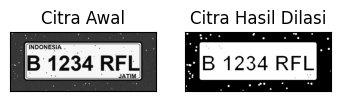

In [9]:
def dilasi_citra(F, w):
  # size image
  p, q = F.shape

  imgD = np.zeros((p, q), dtype=np.uint8)

  # Generate structure element dilasi (SED)
  SED = np.ones((w, w), dtype=np.uint8)
  constant1 = (w - 1) // 2

  # Proses Dilasi
  for i in range(constant1, p - constant1):
    for j in range(constant1, q - constant1):
      temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
      product = temp * SED
      imgD[i, j] = np.max(product)
  return imgD


img_d = cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomer.jpeg', 0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)

w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

[[1 1 1]
 [1 1 1]
 [1 1 1]]


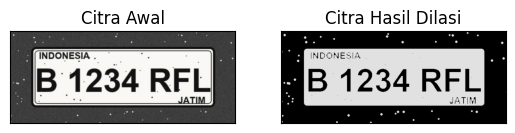

In [11]:
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomer.jpeg')
#img = cv2.imread('morp.jpg',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint16)
dilasi = cv2.dilate(thresh,kernel,iterations = 1)
print(kernel)
plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(dilasi),plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

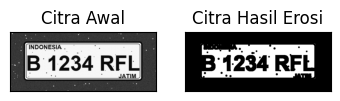

In [13]:
def erosi_citra(F, k):
  # size image
  m, n = F.shape

  # Generate structure element erosi (SE)
  SE = np.ones((k, k), dtype=np.uint8)
  constant = (k - 1) // 2

  imgE = np.zeros((m, n), dtype=np.uint8)

  # Proses Erosi
  for i in range(constant, m - constant):
    for j in range(constant, n - constant):
      temp = F[i - constant : i + constant + 1, j - constant : j + constant + 1]
      product = temp * SE
      imgE[i, j] = np.min(product)

  return imgE


img_e = cv2.imread(
    '/content/drive/MyDrive/PCVK/Images/platnomer.jpeg', 0
)
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

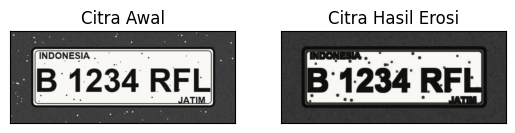

In [14]:
#EROSI LIBRARY
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomer.jpeg')
kernel = np.ones((5,5),np.uint8)
erosion = cv2.erode(img,kernel,iterations = 1)
plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(erosion),plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

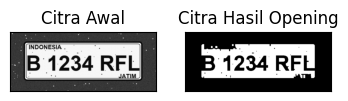

In [15]:
img_o= cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomer.jpeg',0) #
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k=7
imgO = dilasi_citra(erosi_citra(thresho,k),k)
plt.subplot(131),plt.imshow(img_o,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgO,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

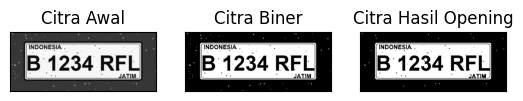

In [16]:
#Dengan Menggunakan Library
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomer.jpeg',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)

openn = cv2.morphologyEx(thresh,cv2.MORPH_OPEN, kernel)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(openn,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

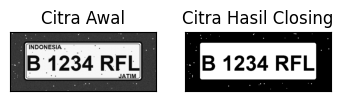

In [17]:
img_c= cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomer.jpeg',0) #
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k=7

imgC = erosi_citra(dilasi_citra(threshc,k),k)
plt.subplot(131),plt.imshow(img_c,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgC,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

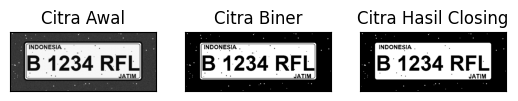

In [18]:

img = cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomer.jpeg',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)

closs = cv2.morphologyEx(thresh,cv2.MORPH_CLOSE, kernel)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(closs,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Cross 3


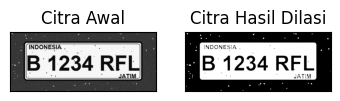

SED = Cross 5


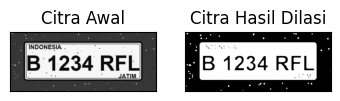

In [19]:
#Dilasi Cross SED
def dilasi_citra(F,w):
  #size image
  p,q= F.shape
  imgD= np.zeros((p,q), dtype=np.uint8)
  #Generate structure element dilasi (SED)
  # SED= np.ones((w,w), dtype=np.uint8)
  SED = np.array([[0, 1, 0],
          [1, 1, 1],
          [0, 1, 0]], dtype = np.uint8)
  constant1= (w-1)//2
  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD

print('SED = Cross 3')
img_d= cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomer.jpeg',0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w=3
imgD = dilasi_citra(thresh,w)
plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

def dilasi_citra(F,w):
#size image
  p,q= F.shape
  imgD= np.zeros((p,q), dtype=np.uint8)
  #Generate structure element dilasi (SED)

  # SED= np.ones((w,w), dtype=np.uint8)
  SED = np.array([[0, 0, 1, 0, 0],
          [0, 0, 1, 0, 0],
          [1, 1, 1, 1, 1],
          [0, 0, 1, 0, 0],
          [0, 0, 1, 0, 0]], dtype = np.uint8)
  constant1= (w-1)//2
  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD
print('SED = Cross 5')
img_d= cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomer.jpeg',0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w=5
imgD = dilasi_citra(thresh,w)
plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Circle 3


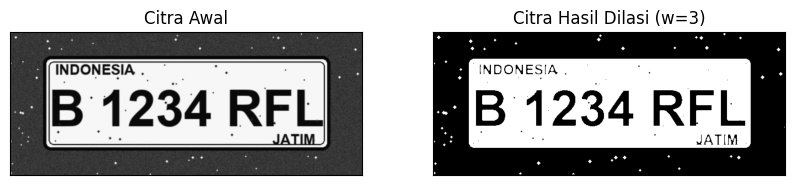

SED = Circle 5


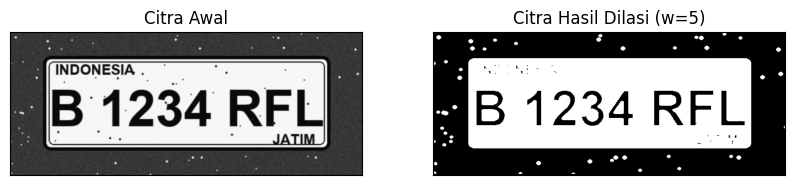

In [20]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Dilasi Circular SED


def dilasi_citra(F, w):
  # size image
  p, q = F.shape
  imgD = np.zeros((p, q), dtype=np.uint8)

  # Generate structure element dilasi (SED) dengan bentuk椭圆/lingkaran
  SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
  constant1 = (w - 1) // 2

  # Proses Dilasi
  for i in range(constant1, p - constant1):
    for j in range(constant1, q - constant1):
      temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
      product = temp * SED
      imgD[i, j] = np.max(product)

  return imgD


# --- Eksekusi untuk SED = Circle 3 ---
print('SED = Circle 3')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomer.jpeg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi (w=3)'), plt.xticks([]), plt.yticks([])
plt.show()

# --- Eksekusi untuk SED = Circle 5 ---
print('SED = Circle 5')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomer.jpeg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi (w=5)'), plt.xticks([]), plt.yticks([])
plt.show()


SE = Rectangle 5x3


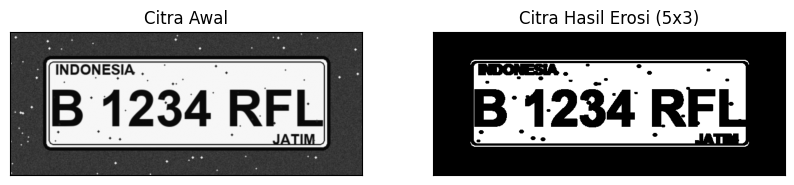

SE = Rectangle 7x5


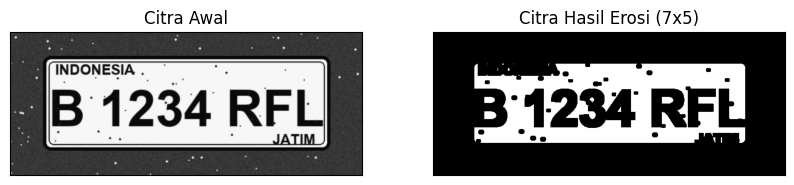

In [21]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Erosi Rectangle SE


def erosi_citra(F, p, l):
  # size image
  m, n = F.shape
  # Generate structure element erosi (SE) persegi panjang
  SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))
  constant1 = (l - 1) // 2
  constant2 = (p - 1) // 2

  imgE = np.zeros((m, n), dtype=np.uint8)

  # Proses Erosi
  for i in range(constant1, m - constant1):
    for j in range(constant2, n - constant2):
      temp = F[
          i - constant1 : i + constant1 + 1, j - constant2 : j + constant2 + 1
      ]
      product = temp * SE
      imgE[i, j] = np.min(product)

  return imgE


# --- Eksekusi untuk SE = Rectangle 5x3 (p=5, l=3) ---
print('SE = Rectangle 5x3')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomer.jpeg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 5
l = 3
imgE = erosi_citra(thresh1, p, l)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi (5x3)'), plt.xticks([]), plt.yticks([])
plt.show()

# --- Eksekusi untuk SE = Rectangle 7x5 (p=7, l=5) ---
print('SE = Rectangle 7x5')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomer.jpeg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 7
l = 5
imgE = erosi_citra(thresh1, p, l)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi (7x5)'), plt.xticks([]), plt.yticks([])
plt.show()

SE = Line Vertikal 3


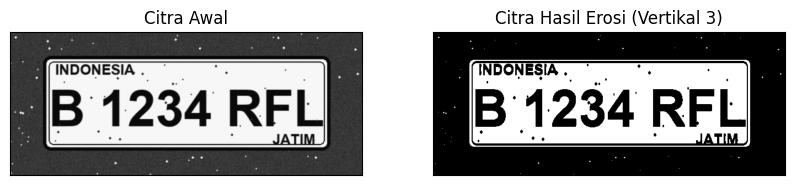

SE = Line Vertikal 5


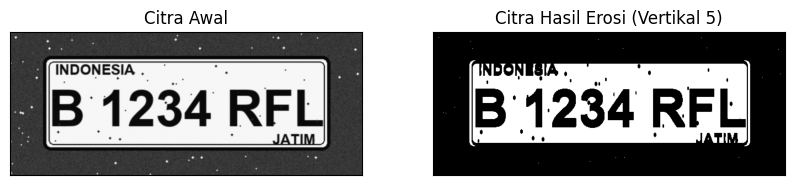

In [22]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Erosi Line Vertikal SE


def erosi_citra(F, k):
  # size image
  m, n = F.shape
  # Generate structure element erosi (SE) line vertikal menggunakan RECT atau ELLIPSE dengan ukuran (1, k)
  SE = cv2.getStructuringElement(cv2.MORPH_RECT, (1, k))
  constant = (k - 1) // 2
  imgE = np.zeros((m, n), dtype=np.uint8)

  # Proses Erosi
  for i in range(constant, m - constant):
    for j in range(constant, n - constant):
      temp = F[i - constant : i - constant + k, j : j + 1]  # disesuaikan untuk line vertikal atau menggunakan slice standar matriks
      # Jika menggunakan slicing standar dari kode asal Anda:
      # temp = F[i-constant:i+constant+1, j-constant:j+constant+1]
      product = temp * SE
      imgE[i, j] = np.min(product)

  return imgE


# --- Eksekusi untuk SE = Line Vertikal 3 (k=3) ---
print('SE = Line Vertikal 3')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomer.jpeg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 3
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi (Vertikal 3)'), plt.xticks([]), plt.yticks([])
plt.show()

# --- Eksekusi untuk SE = Line Vertikal 5 (k=5) ---
print('SE = Line Vertikal 5')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/Images/platnomer.jpeg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi (Vertikal 5)'), plt.xticks([]), plt.yticks([])
plt.show()

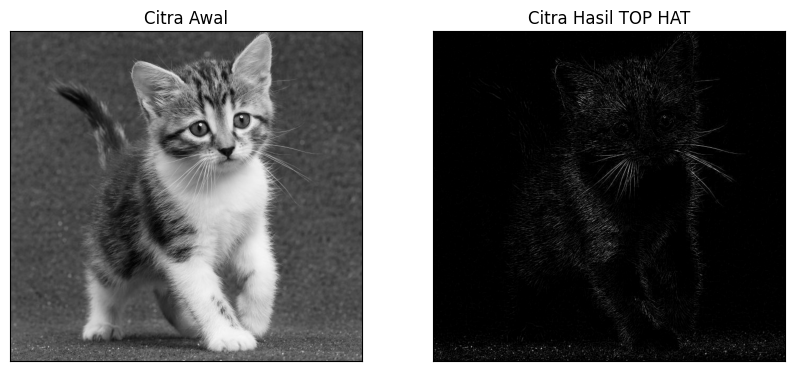

In [24]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Getting the kernel to be used in Top-Hat
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image named 'platNomer.jpg' dan ubah ke grayscale
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/kitten01.jpg')
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation (menggunakan img_gray yang sudah didefinisikan)
tophat_img = cv2.morphologyEx(img_gray, cv2.MORPH_TOPHAT, kernel)

# Menampilkan hasil menggunakan matplotlib
plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.imshow(img_gray, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(122)
plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT')
plt.xticks([]), plt.yticks([])

plt.show()

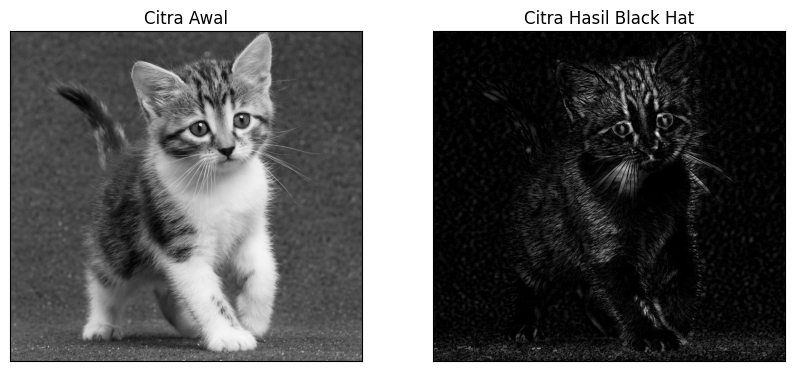

In [25]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Getting the kernel to be used in Black-Hat
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image named 'kitten01.jpg'
img = cv2.imread('/content/drive/MyDrive/PCVK/Images/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Menggunakan Kernel spesifik untuk operasi Black-Hat
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))

# Applying the Black-Hat operation
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

# Menampilkan hasil menggunakan matplotlib
plt.figure(figsize=(10, 5))

plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])

plt.subplot(122)
plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat')
plt.xticks([]), plt.yticks([])

plt.show()

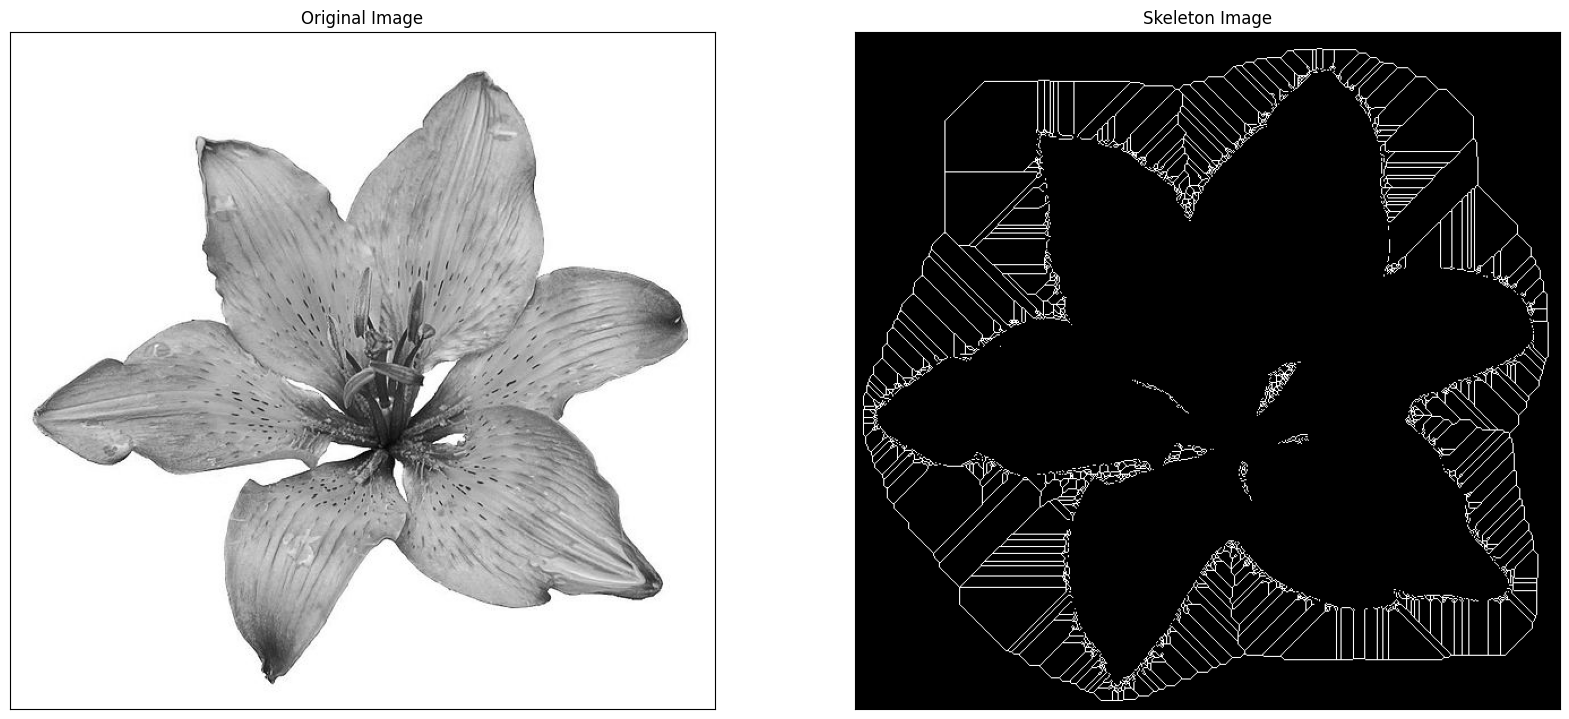

In [26]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image (path disesuaikan ke folder Gambar/lily.jpg atau tetap di Images/)
img = cv.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg', 0)

# Jika Anda ingin tetap menggunakan folder Images seperti path awal Anda, gunakan baris di bawah ini:
# img = cv.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg', 0)

binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20, 20))

plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.xticks([]), plt.yticks([])

plt.subplot(122)
plt.imshow(skeleton, cmap='gray')
plt.title('Skeleton Image')
plt.xticks([]), plt.yticks([])

plt.savefig('binary and bin_skeleton.png')
plt.show()


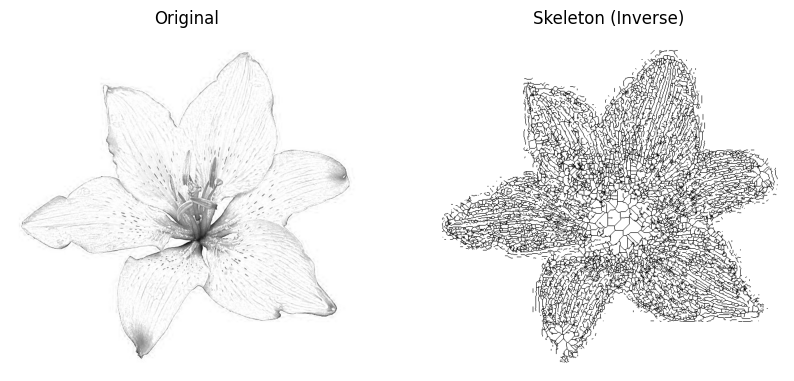

In [27]:
from matplotlib import pyplot as plt
from skimage import filters, io
from skimage.morphology import skeletonize

# read image (sesuaikan path foldernya: Gambar atau Images)
img = io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(img, cmap='gray')
ax[0].set_title('Original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('Skeleton (Inverse)')
ax[1].set_axis_off()

plt.show()

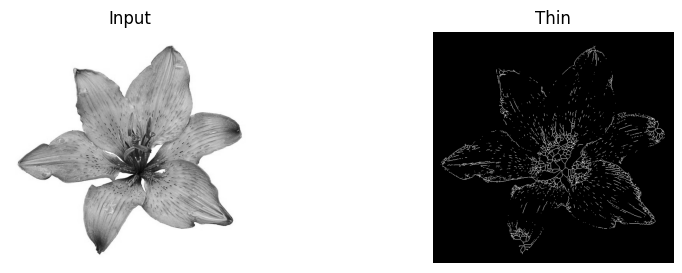

In [28]:

from matplotlib import pyplot as plt
from skimage import color, img_as_float, io, morphology

# read image dan ubah ke grayscale float (sesuaikan path foldernya: Gambar atau Images)
image = img_as_float(
    color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg'))
)

# Jika ingin tetap menggunakan folder Images seperti path awal Anda, gunakan baris ini:
# image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/Images/lily.jpg')))

image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))

ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax0.set_axis_off()

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
ax1.set_axis_off()

plt.savefig('/tmp/char_out.png')
plt.show()

# Tugas Praktikum

Tugas Praktikum Morfologi melibatkan implementasi dataset KTP yang terdapat dalam Modul 7. Dalam tugas ini, kita akan menggunakan semua informasi yang disediakan dalam modul Morfologi dan menerapkan sejumlah nilai tambahan dalam kode sumber. Tujuannya adalah agar citra KTP dapat terbaca dengan baik ketika teknik morfologi diterapkan pada citra tersebut.

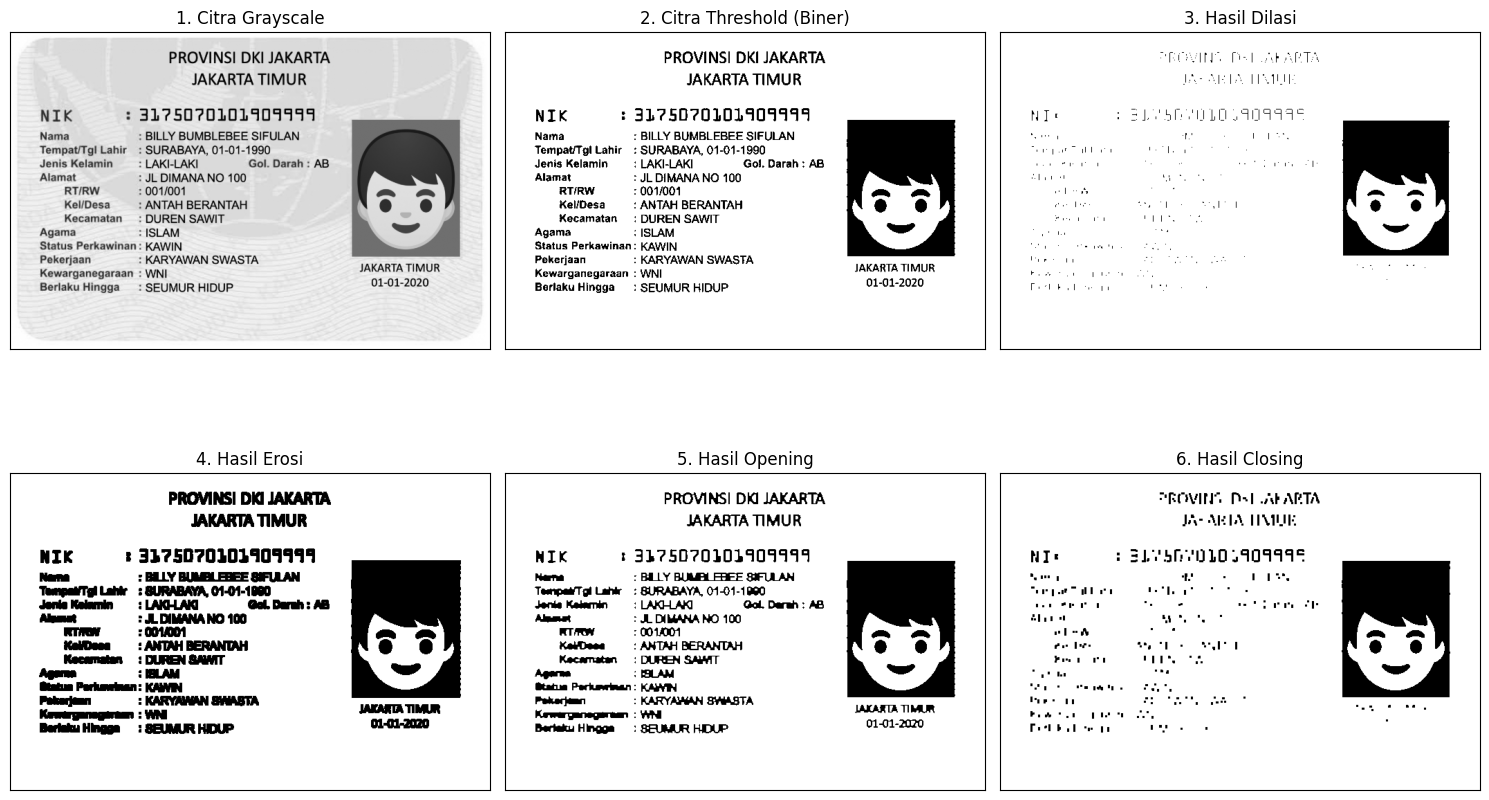

In [29]:
import cv2
from matplotlib import pyplot as plt
import numpy as np

path_ktp = '/content/drive/MyDrive/PCVK/Images/ktp1.jpg'
img = cv2.imread(path_ktp)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

ret, thresh = cv2.threshold(gray, 150, 255, cv2.THRESH_BINARY)

kernel_rect = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

img_dilation = cv2.dilate(thresh, kernel_rect, iterations=1)
img_erosion = cv2.erode(thresh, kernel_rect, iterations=1)
img_opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel_rect)
img_closing = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel_rect)

plt.figure(figsize=(15, 10))

plt.subplot(231), plt.imshow(gray, cmap='gray')
plt.title('1. Citra Grayscale'), plt.xticks([]), plt.yticks([])

plt.subplot(232), plt.imshow(thresh, cmap='gray')
plt.title('2. Citra Threshold (Biner)'), plt.xticks([]), plt.yticks([])

plt.subplot(233), plt.imshow(img_dilation, cmap='gray')
plt.title('3. Hasil Dilasi'), plt.xticks([]), plt.yticks([])

plt.subplot(234), plt.imshow(img_erosion, cmap='gray')
plt.title('4. Hasil Erosi'), plt.xticks([]), plt.yticks([])

plt.subplot(235), plt.imshow(img_opening, cmap='gray')
plt.title('5. Hasil Opening'), plt.xticks([]), plt.yticks([])

plt.subplot(236), plt.imshow(img_closing, cmap='gray')
plt.title('6. Hasil Closing'), plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()